# Vehicle Loan Default Prediction
## A ten-stage credit risk analytics case study

How can vehicle-financing data help prioritize default risk when review capacity
is limited? This portfolio follows a ten-stage modified CRISP-DM lifecycle,
from the business question to recommendations. It combines richer EDA,
controlled experiments, held-out evaluation, and executable routing and
monitoring demonstrations. Every numerical finding is computed from the
shared Python implementation.

**Reading guide:** stages 1-4 establish the question, data, and methods;
stages 5-7 show experiments, selection, and validation; stages 8-10 connect
the analysis to operational design and business decisions.

## Stage 1 - Problem Identification

A credit team must identify applications that deserve closer examination without
overwhelming its queue. Missing a default exposes it to loss; flagging a
non-default consumes capacity and may disrupt a viable application. The task
predicts the provider's `LOAN_DEFAULT` outcome, not lifetime losses.

| Stakeholder | Decision supported | Evidence needed |
| --- | --- | --- |
| Underwriting | Prioritize review | Recall, precision, workload |
| Risk management | Assess model quality | ROC-AUC, average precision, uncertainty, stability |
| Operations | Plan staffing | Capacity scenarios and frozen routing rules |
| Business leadership | Decide whether a pilot is justified | Assumption-based costs and measured pilot outcomes |

Primary selection uses validation ROC-AUC. Operational evaluation adds a 25%
validation review cap. Scores are uncalibrated ranking signals, not instructions
to approve or reject a loan.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if not (ROOT / 'src/credit_risk.py').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src/credit_risk.py').exists():
    raise RuntimeError('Start Jupyter from the repository root or notebooks directory.')
sys.path.insert(0, str(ROOT / 'src'))
from credit_risk import Config, TARGET, load_data, split_data, engineer_features, build_models, run_experiment
from eda import run_eda
CONFIG = Config()
DATA, REPORTS = ROOT / 'data/raw/train.csv', ROOT / 'reports'
def table(name):
    return pd.read_csv(REPORTS / 'tables' / f'{name}.csv')
def chart(name):
    display(Image(filename=str(REPORTS / 'figures' / f'{name}.png')))

## Stage 2 - Sourcing of Raw Data

The LTFS vehicle-loan data contains loan and asset amounts, LTV, employment,
bureau scores, account history, demographic dates, sourcing identifiers, and
document indicators. The local files originate from the Kaggle mirror of the
LTFS Data Science FinHack dataset. We retain the supplied binary outcome
definition rather than infer a longer delinquency horizon.

`test.csv` is unlabeled. Reported test metrics use a held-out partition of labeled
`train.csv`. Application IDs must be unique and are excluded from modeling.
Raw records remain local; published outputs contain aggregates and schema
information without individual applicant previews.

In [2]:
raw = load_data(DATA, CONFIG)
train, validation, test = split_data(raw, CONFIG)
profile = pd.DataFrame([
    {'partition': name, 'applications': len(frame), 'default_rate': frame[TARGET].mean()}
    for name, frame in [('All labeled data', raw), ('Training', train),
                        ('Validation', validation), ('Held-out test', test)]
])
display(profile.style.format({'applications': '{:,.0f}', 'default_rate': '{:.2%}'}))
display(Markdown(f'**Data:** {len(raw):,} applications, {raw.shape[1]} columns. '
                 f'**Default prevalence:** {raw[TARGET].mean():.2%}. '
                 'The stratified 60/20/20 split is fixed at seed 42.'))

,partition,applications,default_rate
0,All labeled data,"233,154",21.71%
1,Training,"139,892",21.71%
2,Validation,"46,631",21.71%
3,Held-out test,"46,631",21.71%


**Data:** 233,154 applications, 41 columns. **Default prevalence:** 21.71%. The stratified 60/20/20 split is fixed at seed 42.

## Stage 3 - Data Preprocessing & Preparation
### 3.1 Data quality and class balance

Label-based exploration uses training only. We inspect missingness, unique
values, duplicate IDs, implausible ages, and class balance. Missing employment
remains an explicit category; numerical medians are learned from training.
An approve-all baseline explains why accuracy alone is insufficient.

,column,dtype,missing_count,missing_share,unique_values
9,EMPLOYMENT_TYPE,object,4636,0.03314,2
0,UNIQUEID,int64,0,0.00000,139892
31,SEC_SANCTIONED_AMOUNT,int64,0,0.00000,1419
23,PRI_OVERDUE_ACCTS,int64,0,0.00000,17
24,PRI_CURRENT_BALANCE,int64,0,0.00000,45529
25,PRI_SANCTIONED_AMOUNT,int64,0,0.00000,28596
26,PRI_DISBURSED_AMOUNT,int64,0,0.00000,30670
27,SEC_NO_OF_ACCTS,int64,0,0.00000,34
28,SEC_ACTIVE_ACCTS,int64,0,0.00000,20
29,SEC_OVERDUE_ACCTS,int64,0,0.00000,8


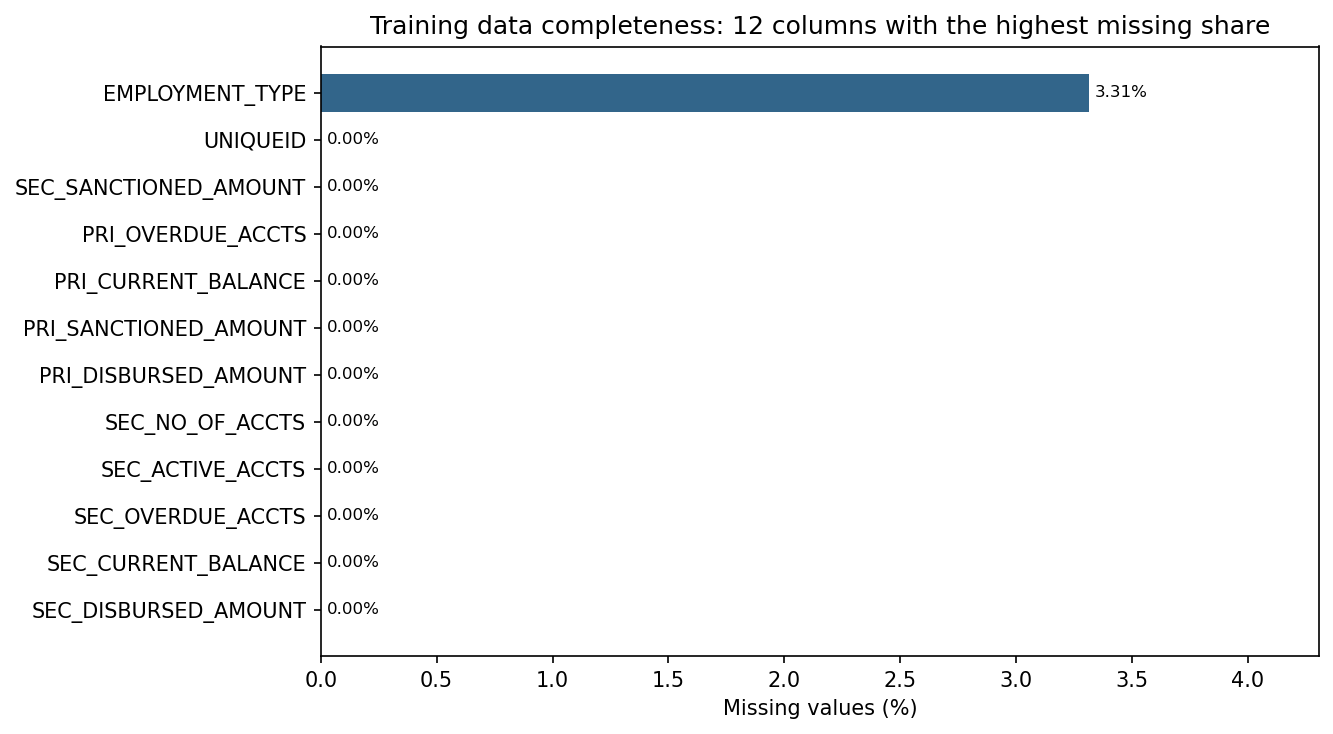

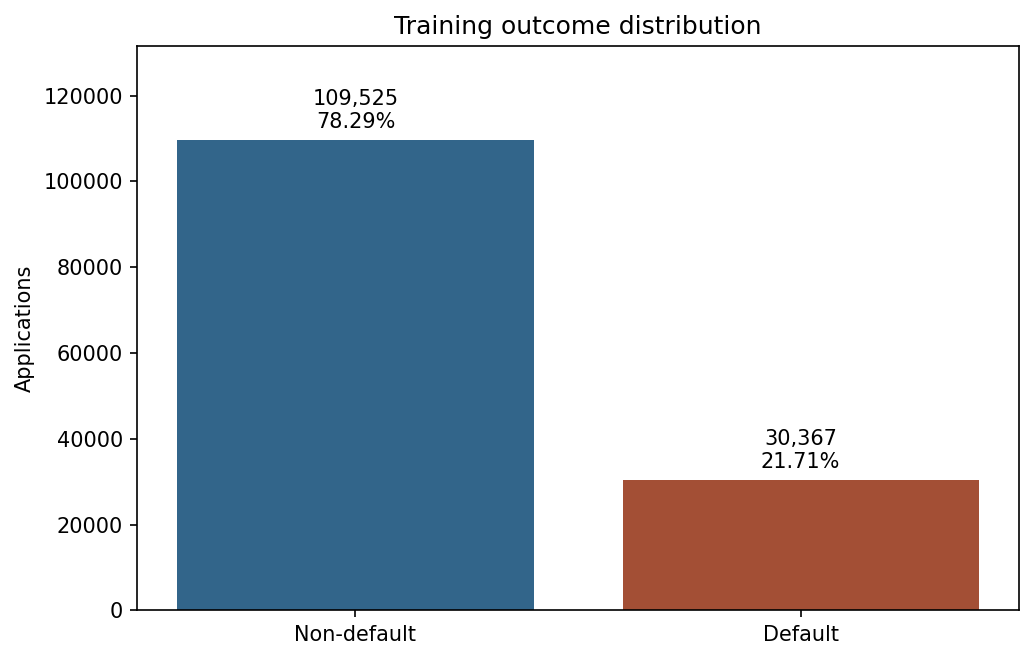

Duplicate training IDs: **0**. Invalid or missing engineered ages: **0**. Predicting every training case as non-default gets **78.29%** accuracy and zero default recall.

In [3]:
eda = run_eda(train, REPORTS)
display(table('data_quality').sort_values('missing_share', ascending=False))
chart('missingness')
chart('target_distribution')
display(Markdown(f'Duplicate training IDs: **{eda["duplicate_application_ids"]}**. '
                 f'Invalid or missing engineered ages: **{eda["invalid_age_count"]:,}**. '
                 f'Predicting every training case as non-default gets **{1-train[TARGET].mean():.2%}** '
                 'accuracy and zero default recall.'))

### 3.2 Financial distributions, loan size, and LTV

Financial distributions expose skew and extreme amounts. Histograms clip
display values at training p99 and use log count axes; model inputs are not
clipped by this display operation. Rate charts show counts and pointwise 95%
Wilson intervals. Intervals do not adjust for multiple comparisons or entity
dependence. Associations do not establish causal effects of changed loan terms.

,Unnamed: 0,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
0,DISBURSED_AMOUNT,139892.0,54375.812055,12930.881179,13320.00,26638.7300,47145.00,53803.0,60410.00,74123.00,95490.00,987354.0
1,ASSET_COST,139892.0,75890.399794,18824.473542,37000.00,47300.0000,65725.00,70960.5,79221.00,109780.00,156502.71,1328954.0
2,LTV,139892.0,74.751956,11.451750,10.03,39.3691,68.88,76.8,83.66,89.38,89.95,95.0
3,PRI_CURRENT_BALANCE,139892.0,166175.624968,947988.845431,-2018309.00,0.0000,0.00,0.0,34771.00,810130.25,2908810.37,96524920.0


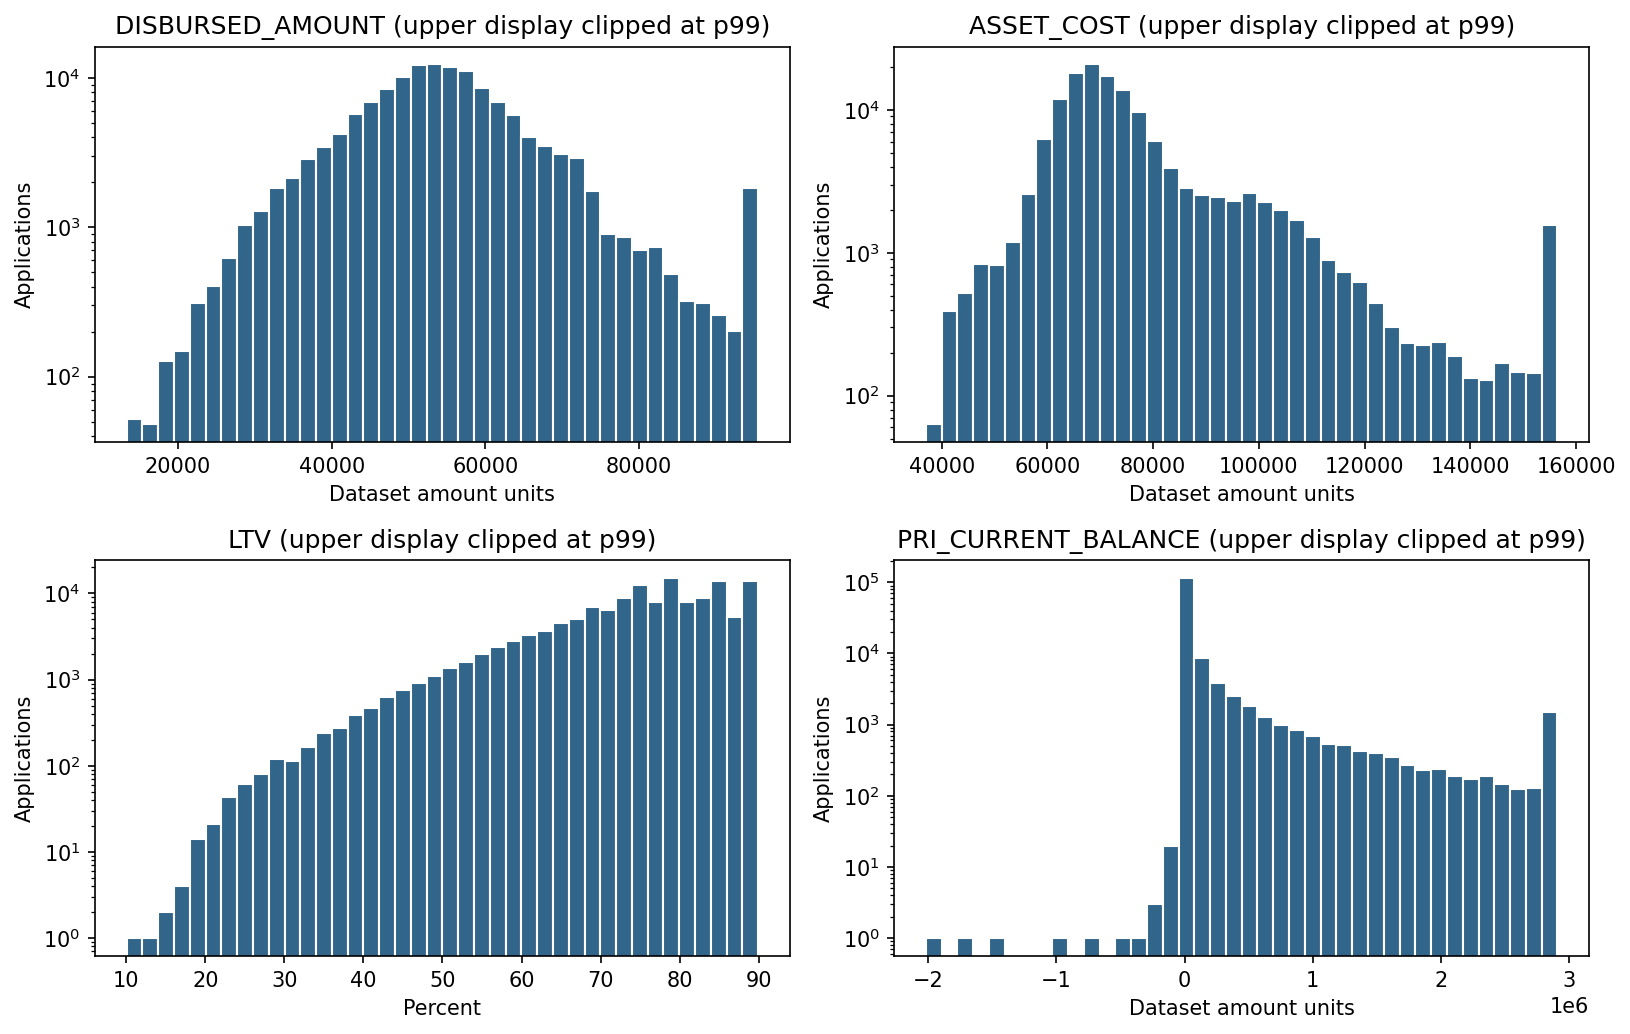

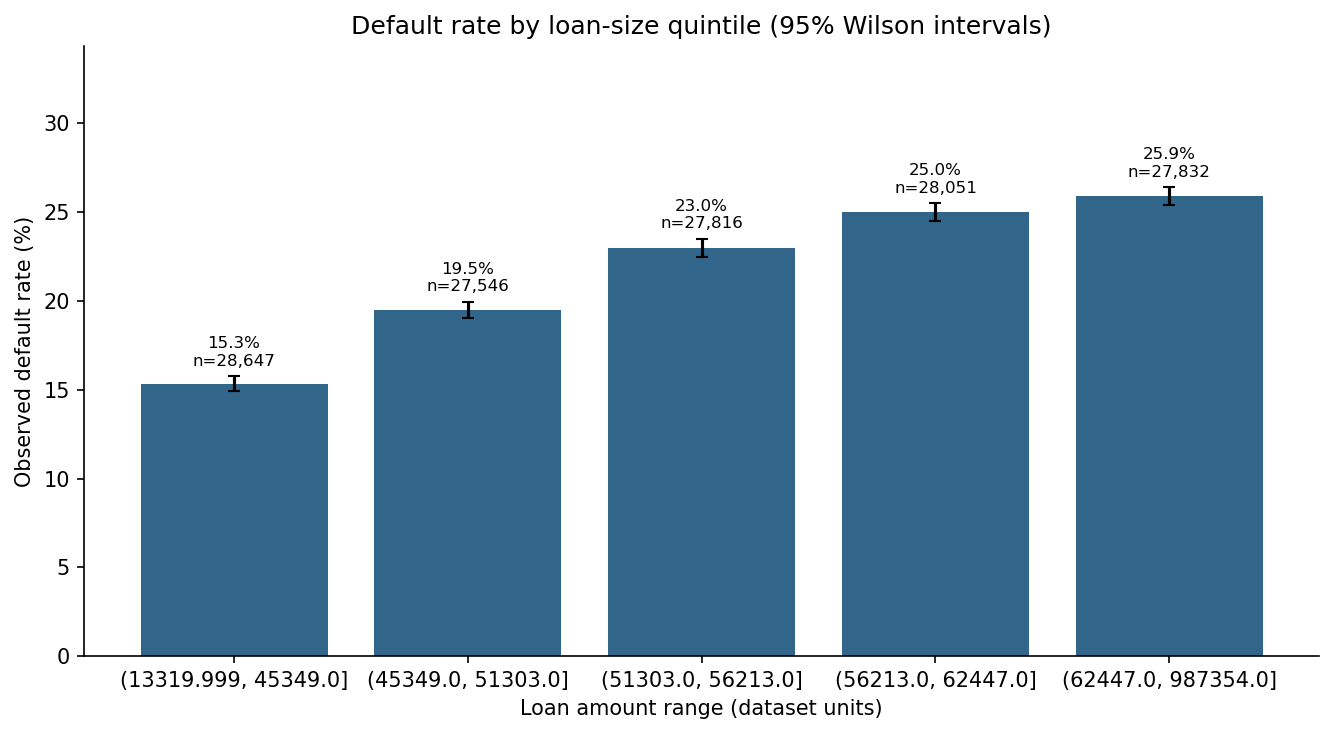

,group,applications,defaults,default_rate,ci_low,ci_high,application_share
0,0-60,15606,2133,0.136678,0.131378,0.142157,0.111557
1,60-70,23811,4205,0.176599,0.171808,0.181495,0.170210
2,70-80,51267,11324,0.220883,0.217313,0.224495,0.366476
3,80-90,48677,12592,0.258685,0.254814,0.262594,0.347961
4,90-100,531,113,0.212806,0.180120,0.249617,0.003796


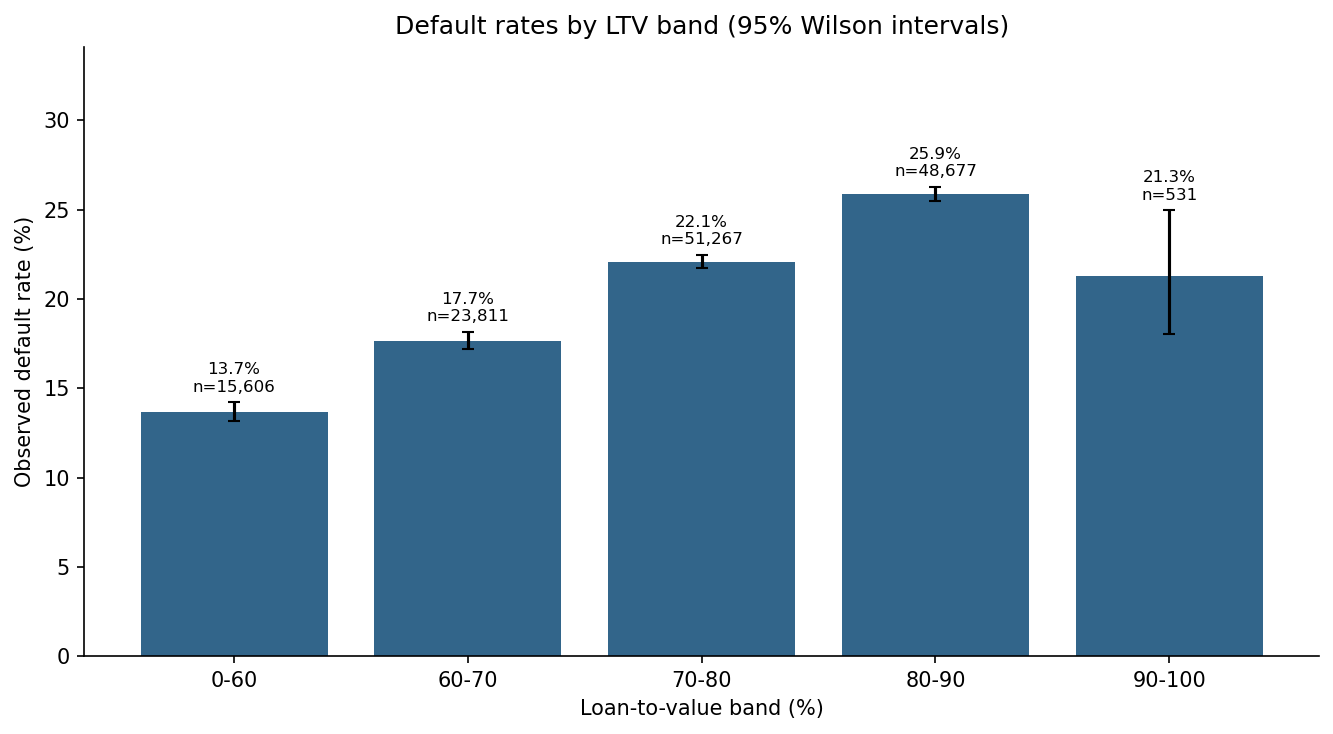

Training default rate is **25.82%** above 80% LTV vs **19.48%** at or below 80%. The small highest-LTV group is not a precise estimate of a monotonic trend.

In [4]:
display(table('financial_summary'))
chart('financial_distributions')
chart('loan_amount_default_rates')
display(table('ltv_default_rates'))
chart('ltv_default_rates')
display(Markdown(f'Training default rate is **{eda["training_ltv_above_80_default_rate"]:.2%}** '
                 f'above 80% LTV vs **{eda["training_ltv_at_most_80_default_rate"]:.2%}** at or below 80%. '
                 'The small highest-LTV group is not a precise estimate of a monotonic trend.'))

### 3.3 Bureau score and employment

A score of zero is analyzed separately and is not automatically interpreted as
no credit history. Provider descriptions supply additional context. Bureau
groups below 500 training cases remain in CSV but are omitted from the chart.
Employment differences are descriptive rather than lending eligibility rules.

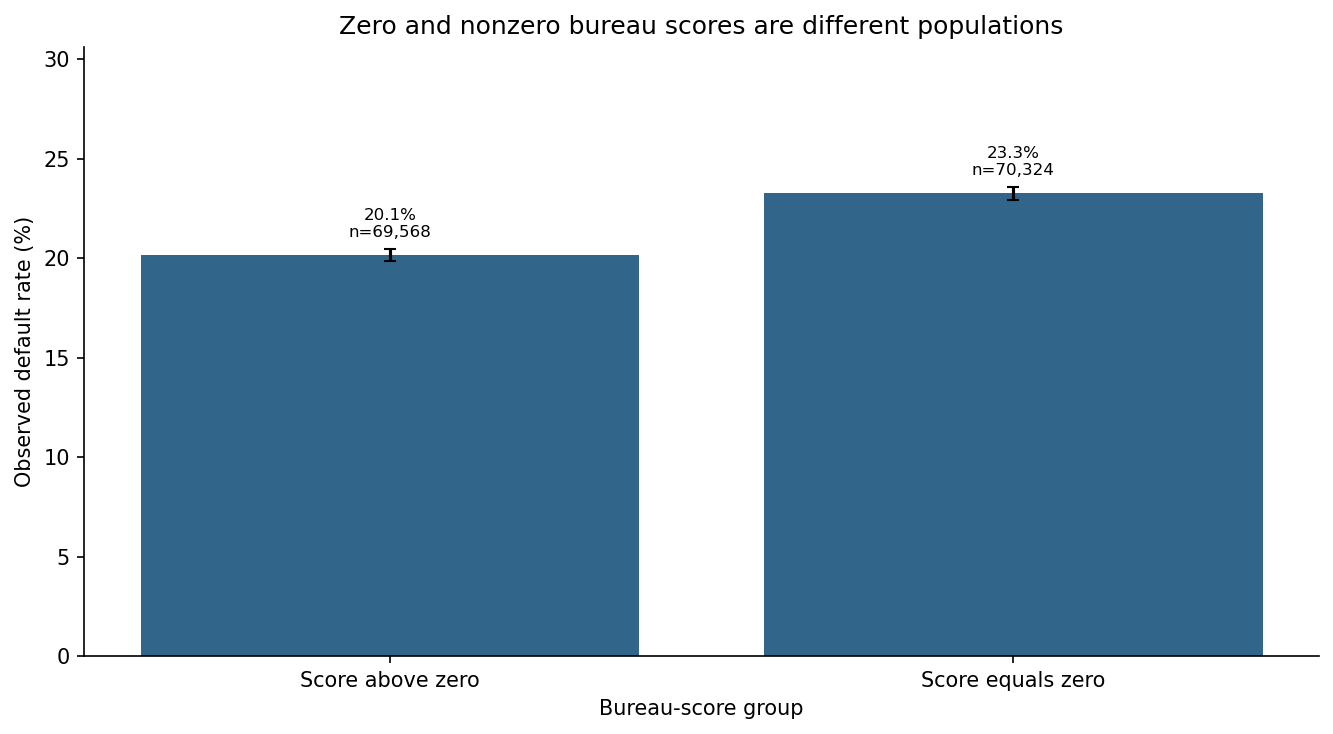

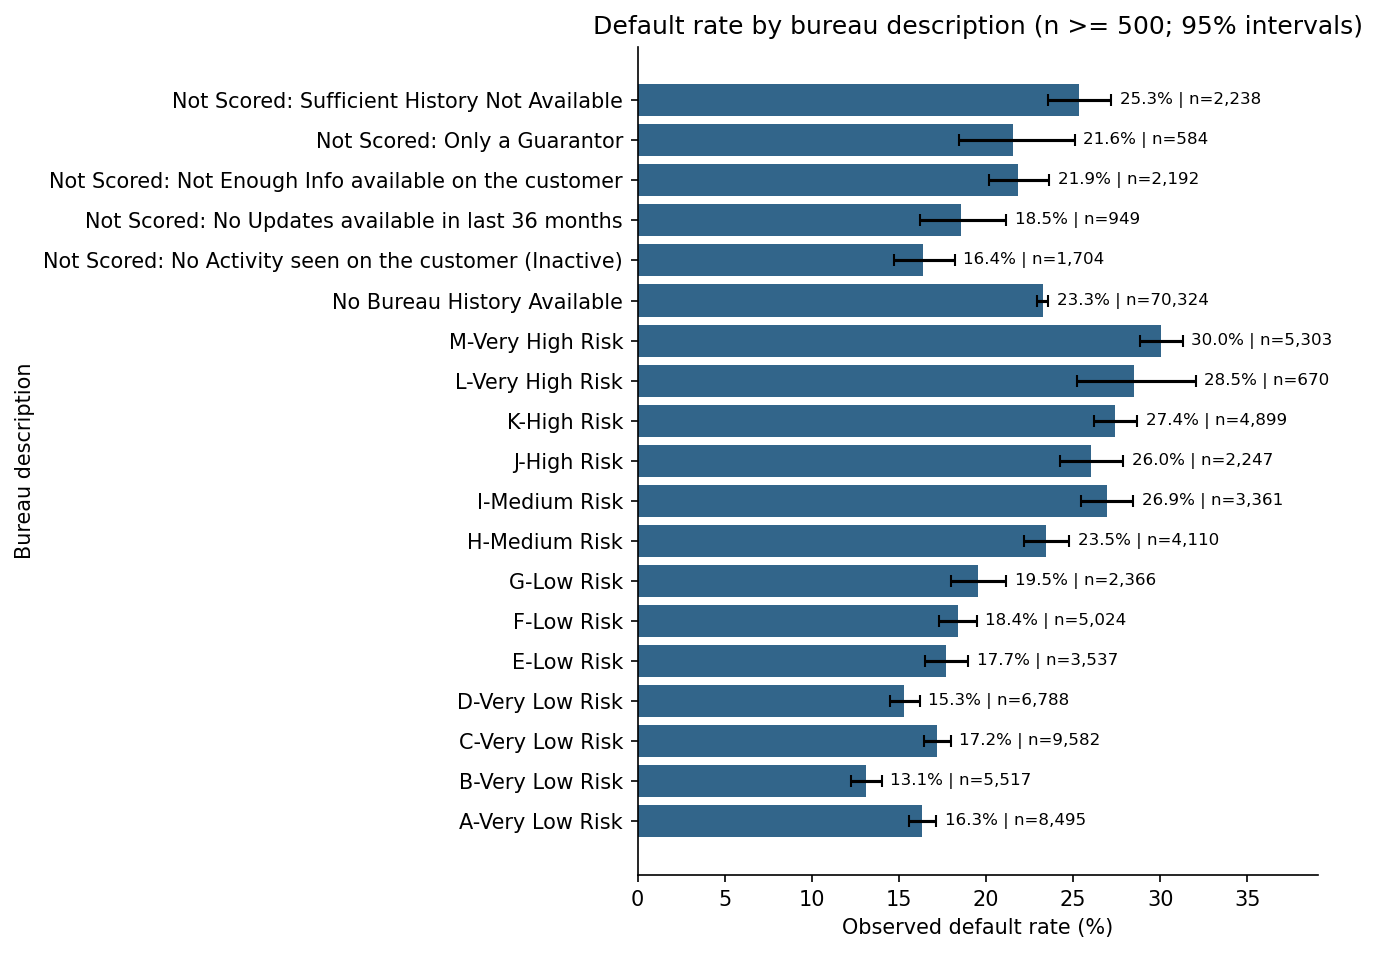

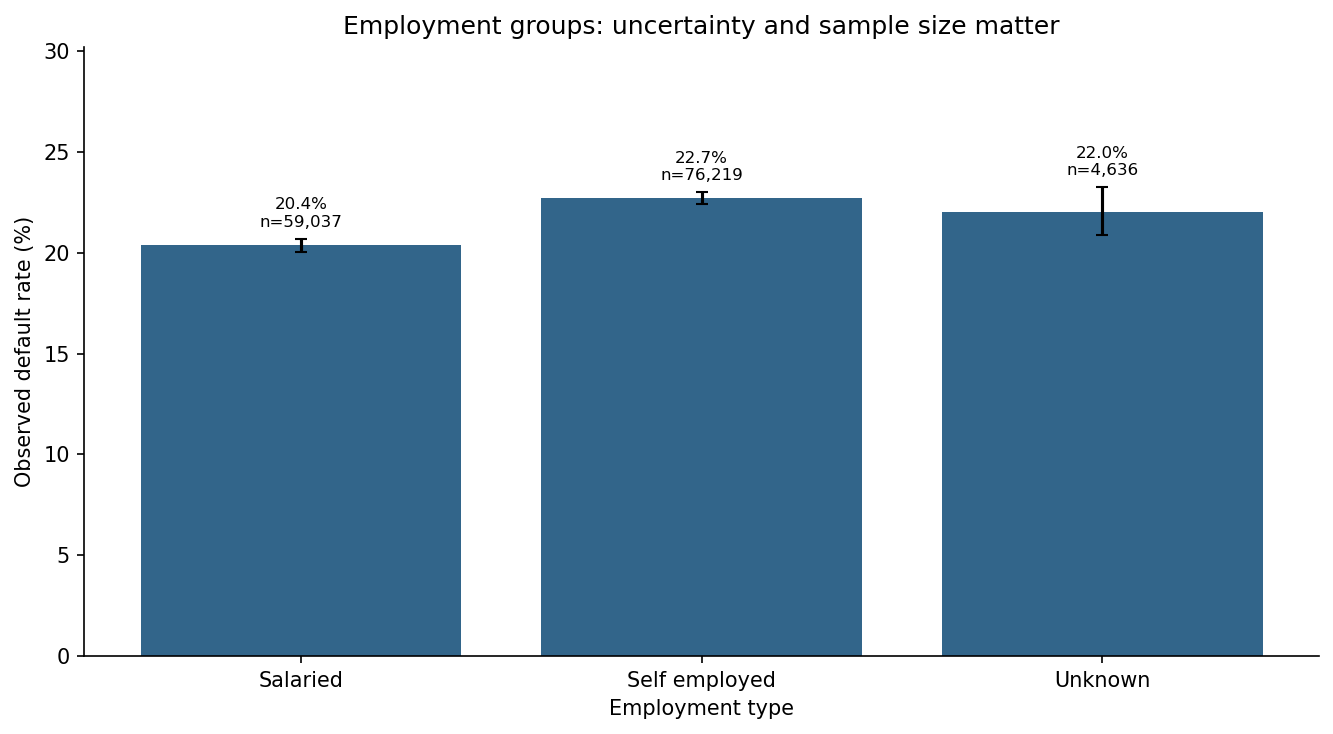

,group,applications,defaults,default_rate,ci_low,ci_high,application_share
0,Score above zero,69568,14016,0.201472,0.198508,0.204469,0.497298
1,Score equals zero,70324,16351,0.232510,0.229402,0.235646,0.502702


**50.27%** of training applications have a zero bureau score, making its handling a material modeling choice.

In [5]:
chart('bureau_score_presence')
chart('bureau_categories')
chart('employment_default_rates')
display(table('bureau_score_presence'))
display(Markdown(f'**{eda["training_zero_bureau_score_share"]:.2%}** of training applications '
                 'have a zero bureau score, making its handling a material modeling choice.'))

### 3.4 Inquiries, recent delinquency, and age

Inquiries and overdue accounts summarize recent credit activity and repayment
stress. Counts of three or more are grouped to reduce sparse comparisons. Age
groups describe this dataset; operational use requires subgroup and fairness review.

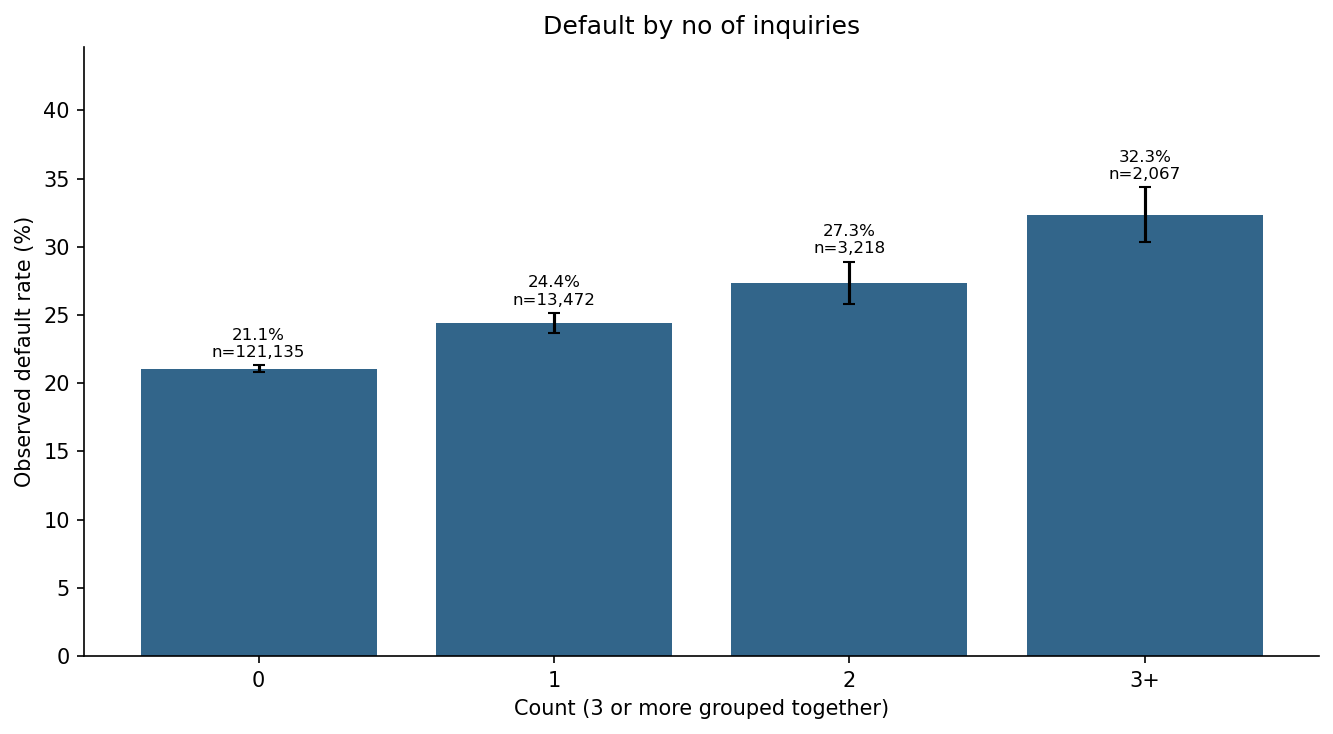

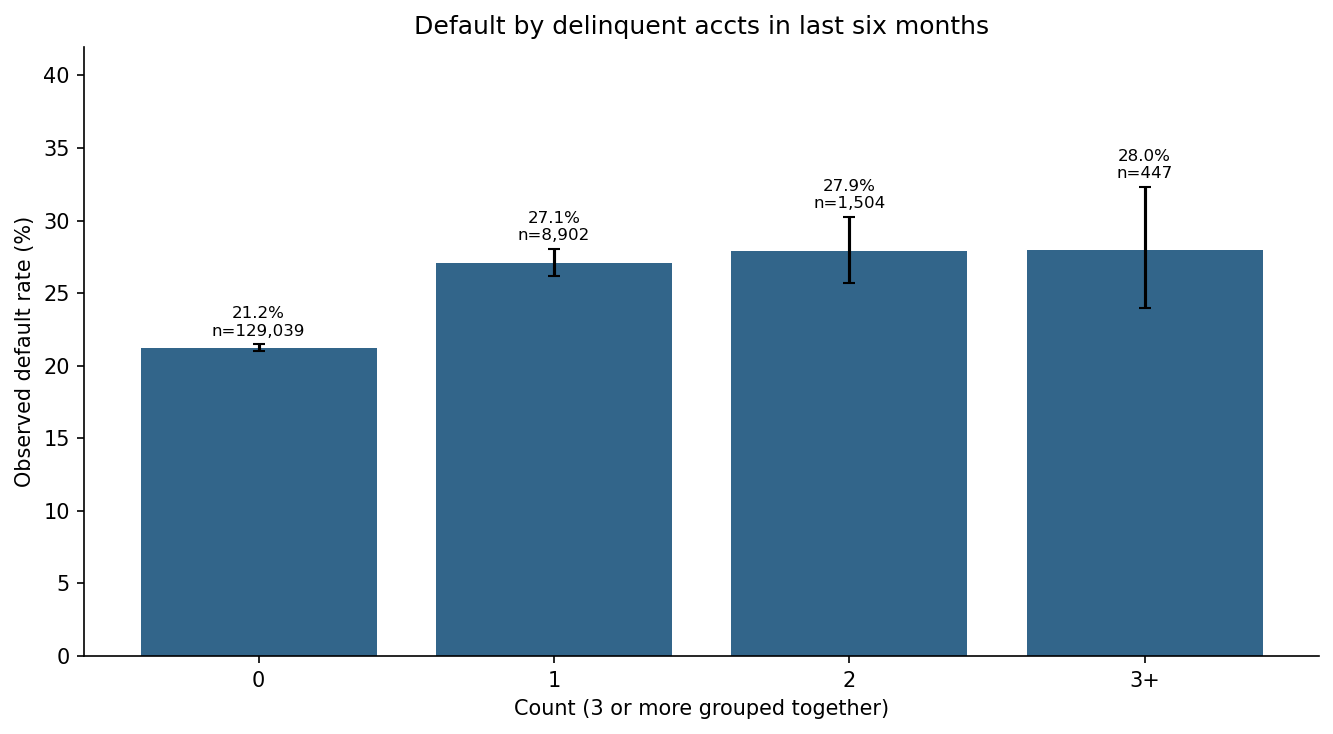

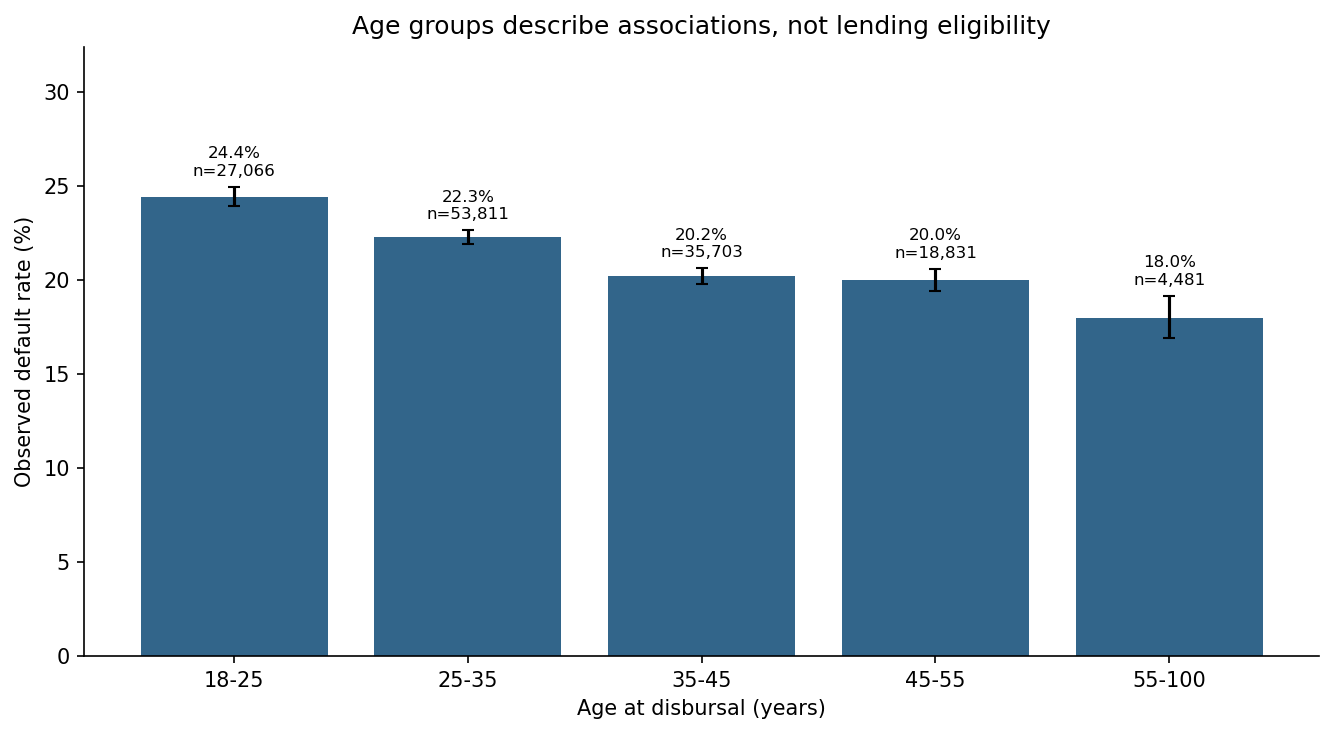

,group,applications,defaults,default_rate,ci_low,ci_high,application_share
0,0,129039,27409,0.212409,0.210186,0.214649,0.922419
1,1,8902,2413,0.271063,0.261929,0.280394,0.063635
2,2,1504,420,0.279255,0.257166,0.302469,0.010751
3,3+,447,125,0.279642,0.240047,0.322992,0.003195


In [6]:
chart('inquiries_default_rates')
chart('delinquency_default_rates')
chart('age_default_rates')
display(table('delinquency_default_rates'))

### 3.5 Calendar coverage, sourcing concentration, and feature relationships

Monthly training rates describe a short historical window, not out-of-time
model performance. Sourcing concentration and sparse entities may limit
transfer of dealer, staff, and geographic encodings. Only concentration
summaries are exported, without staff or dealer ID lists.

Pearson correlation measures linear association. Weak correlation does not
prove nonlinearity or guarantee superior tree-model results. The LTV/bureau
matrix explores a joint association without causal claims.

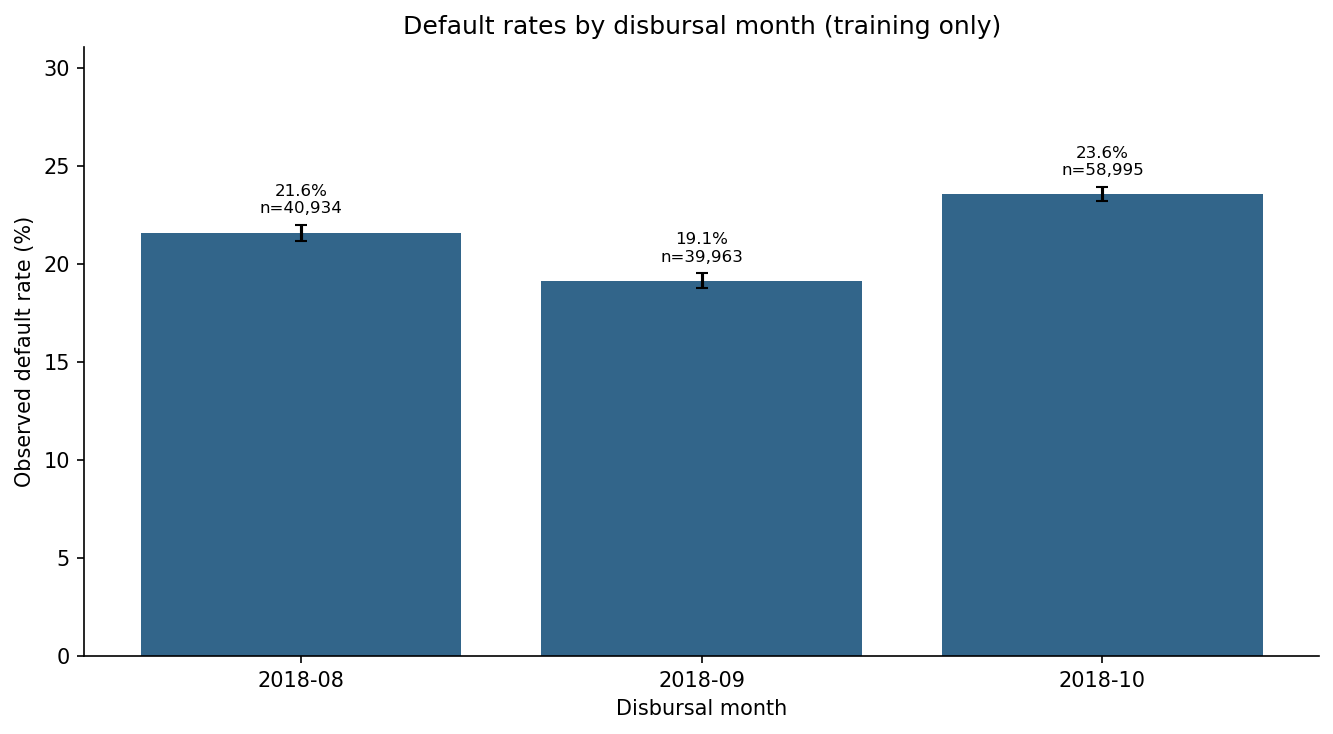

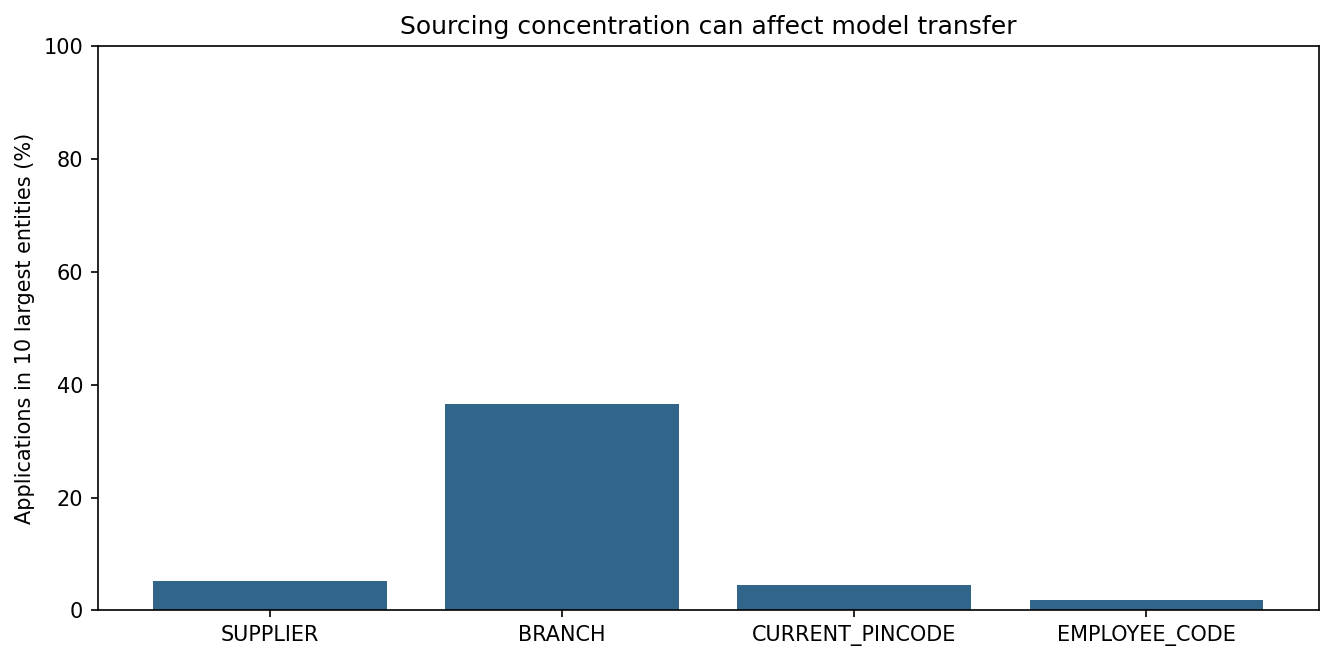

,entity_type,unique_entities,top_10_volume_share,entities_with_fewer_than_30_applications,applications_in_small_entities_share
0,SUPPLIER_ID,2876,0.052512,1672,0.131337
1,BRANCH_ID,82,0.366783,0,0.000000
2,CURRENT_PINCODE_ID,6261,0.045735,4964,0.289330
3,EMPLOYEE_CODE_ID,3245,0.018343,1259,0.126440


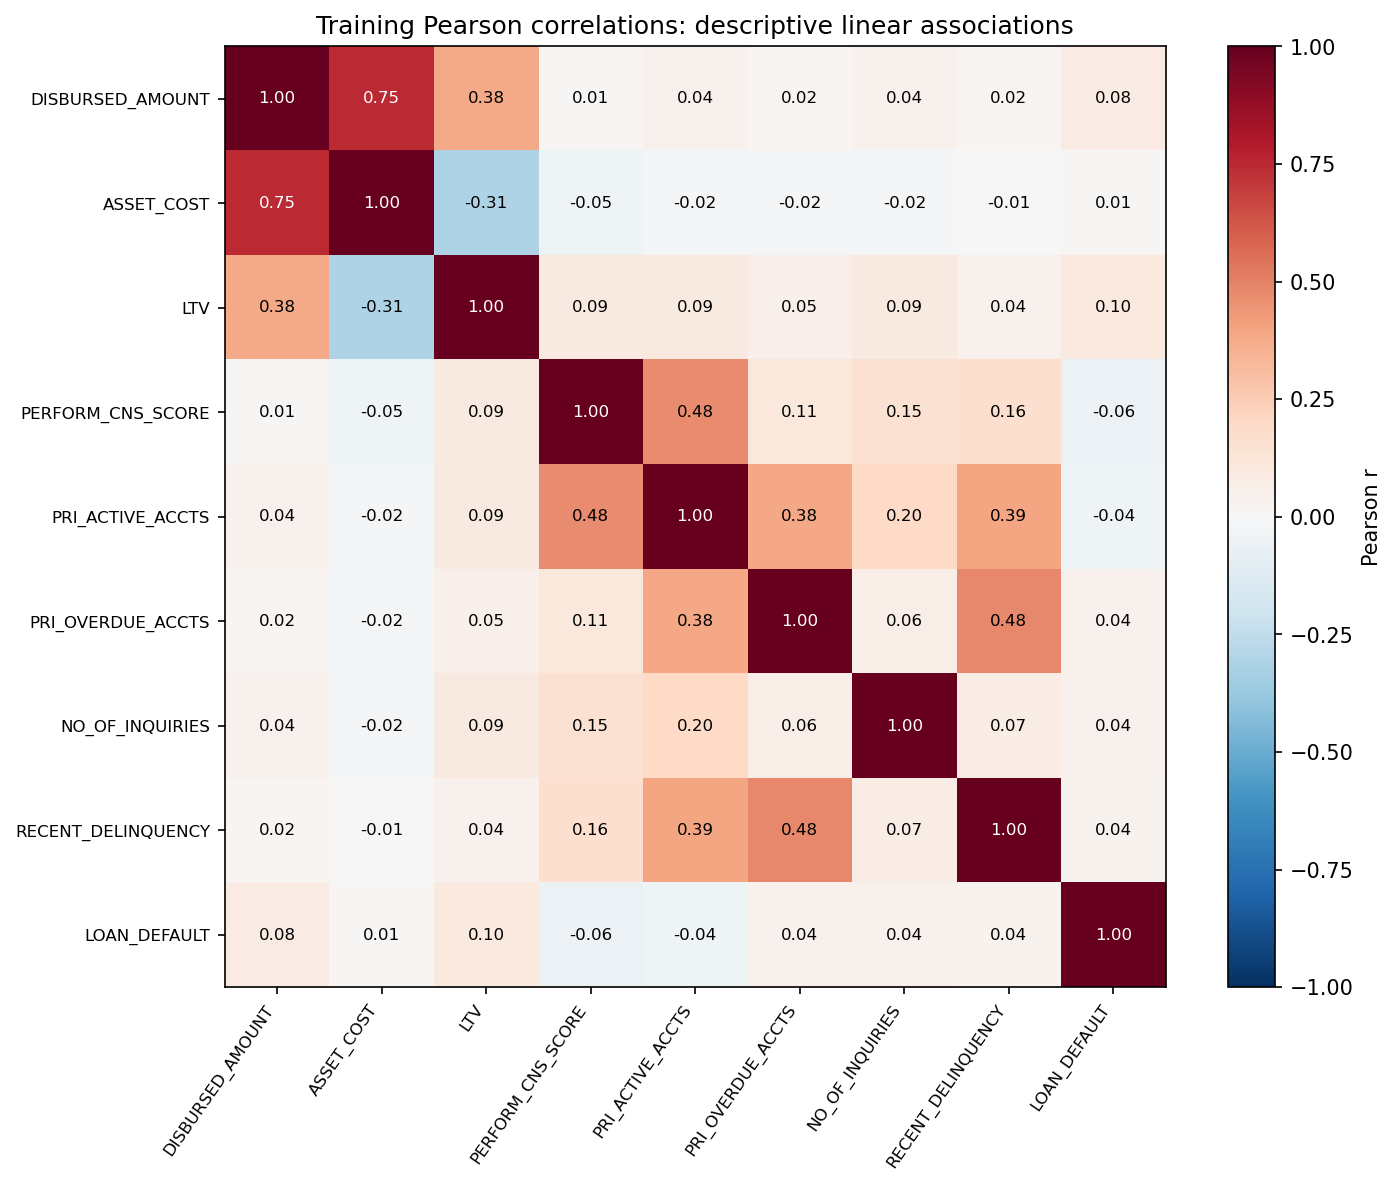

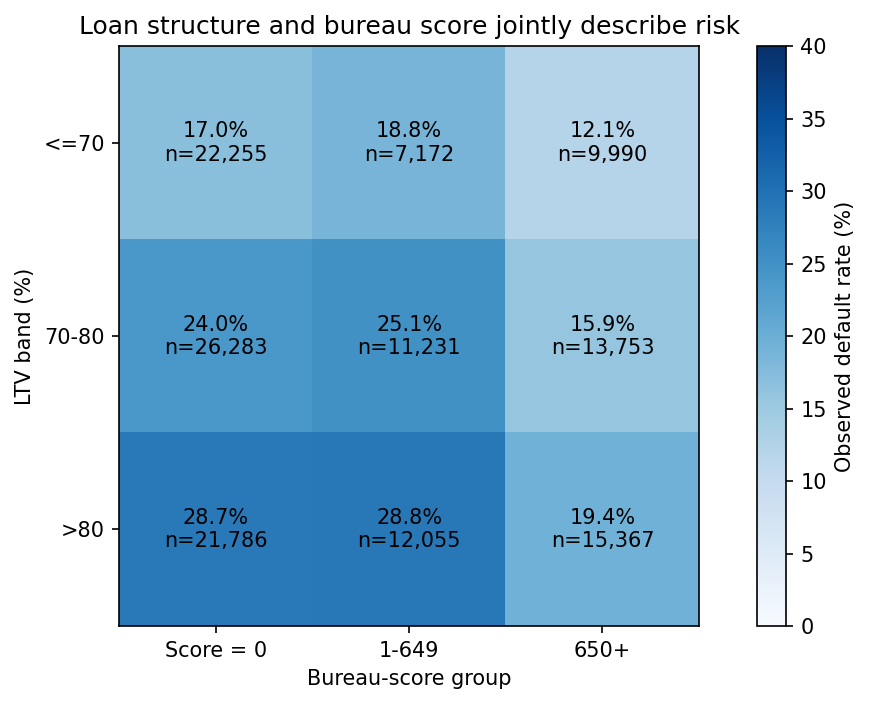

Training disbursal coverage: **2018-08-01 to 2018-10-31**. The EDA exports **15 charts** and supporting tables.

In [7]:
chart('monthly_default_rates')
chart('entity_concentration')
display(table('entity_concentration'))
chart('correlation_matrix')
chart('ltv_bureau_interaction')
display(Markdown(f'Training disbursal coverage: **{eda["disbursal_start"]} to {eda["disbursal_end"]}**. '
                 f'The EDA exports **{eda["chart_count"]} charts** and supporting tables.'))

### 3.6 Feature engineering and leakage boundaries

Dates become age and calendar fields; account durations become months. Down
payment, loan-to-asset, overdue-account, and utilization ratios add row-level
context. Invalid ratios become missing. Application IDs and raw date/duration
strings are excluded. Numerical medians are fitted on training only.

Smoothed categorical target encoding internally cross-fits five training folds.
Validation and test use training-only mappings; unseen categories use the
training prior. Logistic regression fits its scaler on training only. Outer
performance CV rebuilds preprocessing inside each outer training fold, including
its own internal encoding folds.

In [8]:
engineered = engineer_features(train)
display(pd.DataFrame({'feature': engineered.columns,
                      'dtype': engineered.dtypes.astype(str).to_numpy(),
                      'training_missing_share': engineered.isna().mean().to_numpy()}))

,feature,dtype,training_missing_share
0,DISBURSED_AMOUNT,int64,0.000000
1,ASSET_COST,int64,0.000000
2,LTV,float64,0.000000
3,BRANCH_ID,object,0.000000
4,SUPPLIER_ID,object,0.000000
5,MANUFACTURER_ID,object,0.000000
6,CURRENT_PINCODE_ID,object,0.000000
7,EMPLOYMENT_TYPE,object,0.000000
8,STATE_ID,object,0.000000
9,EMPLOYEE_CODE_ID,object,0.000000


## Stage 4 - AI/ML Algorithm Identification

| Model | Experimental role | Main trade-off |
| --- | --- | --- |
| Logistic Regression | Linear weighted baseline | Simplicity vs limited interaction modeling |
| Random Forest | Bagged nonlinear baseline | Compute and fitting capacity |
| XGBoost | Regularized boosting | Learning rate, depth, and weights |
| LightGBM | Efficient boosted trees | Leaf complexity and small categories |
| CatBoost | Second boosting implementation | Uses the common encoded matrix for comparison |
| Fixed weighted blend | Validation-only ensemble diagnostic | Complexity may add little ranking value |

All primary estimators see identical splits and features. Weighting is also
tested through ablation. No exhaustive parameter search is claimed.

In [9]:
definitions = build_models(train[TARGET], CONFIG)
keys = ['n_estimators', 'iterations', 'learning_rate', 'max_depth', 'num_leaves',
        'min_child_samples', 'reg_lambda', 'class_weight', 'auto_class_weights', 'scale_pos_weight']
parameters = []
for name, estimator in definitions.items():
    model = estimator.named_steps['model'] if name == 'Logistic Regression' else estimator
    params = model.get_params()
    parameters.append({'model': name, **{key: str(params[key]) for key in keys if key in params}})
display(pd.DataFrame(parameters).fillna('-'))

,model,class_weight,n_estimators,max_depth,learning_rate,reg_lambda,scale_pos_weight,num_leaves,min_child_samples,iterations,auto_class_weights
0,Logistic Regression,balanced,-,-,-,-,-,-,-,-,-
1,Random Forest,balanced,300,12,-,-,-,-,-,-,-
2,XGBoost,-,1000,5,0.015,5,3.606711232588007,-,-,-,-
3,LightGBM,balanced,1200,-1,0.01,5,-,31,100,-,-
4,CatBoost,-,-,-,0.03,-,-,-,-,1500,Balanced


## Stage 5 - Training & Testing the Model

| Experiment | Changed factor | Fixed conditions |
| --- | --- | --- |
| Five-model benchmark | Estimator family | Split, encoded data, selection metric |
| Class-weight ablation | Disable weighting | Primary family and features |
| Sourcing ablation | Remove six entity/geographic IDs | Remaining features and model settings |
| Engineered-feature ablation | Remove derived numeric features | Retained raw predictors and settings |
| Parameter challengers | Smaller trees / stronger regularization for LightGBM | Same training and validation rows |
| Fixed blend | XGB 0.35, LGBM 0.35, CatBoost 0.30 | No optimized weights |
| Five-fold validation | Outer training fold | Preprocessing refitted in every fold |
| Four-seed stability | Estimator seeds 42, 7, 123, 2024 | Split and encoding fixed |
| Sensitivity | 45 cost/capacity assumptions | Validation predictions fixed |

The primary selection scope is the five fixed model families. Challengers
diagnose sensitivity and do not silently replace that model through test
inspection. The next cell runs the shared pipeline and regenerates all
evidence, including final test evaluation, routing, and monitoring summaries.
Execution takes several minutes on the reference machine.

In [10]:
results = run_experiment(DATA, REPORTS, CONFIG)
display(table('ablation_experiments'))
display(table('hyperparameter_challengers'))
display(table('ensemble_validation'))

Logistic Regression: validation AUC 0.6587


Random Forest: validation AUC 0.6618


XGBoost: validation AUC 0.6723


LightGBM: validation AUC 0.6730


CatBoost: validation AUC 0.6726


Extended: class weighting and feature ablations complete


... (6 outputs left out)

Selected LightGBM; test AUC 0.6735; threshold 0.585


,experiment,validation_roc_auc,validation_average_precision,fit_seconds,feature_count,auc_change_from_primary
0,Primary selected model,0.672967,0.355536,NaN,NaN,0.000000
1,Without class weighting,0.673080,0.356734,10.948630,NaN,0.000113
2,Without sourcing and geographic IDs,0.649393,0.329489,9.361029,44.0,-0.023574
3,Without engineered numeric features,0.665283,0.345074,8.337006,35.0,-0.007684


,experiment,validation_roc_auc,validation_average_precision,changed_parameters
0,Primary selected model,0.672967,0.355536,NaN
1,Smaller trees (15 leaves),0.672341,0.354407,"{""num_leaves"": 15}"
2,Stronger regularization,0.673001,0.355709,"{""min_child_samples"": 200, ""reg_lambda"": 20}"


,experiment,validation_roc_auc,validation_average_precision
0,Primary selected model,0.672967,0.355536
1,Fixed blend: XGB 0.35 / LGBM 0.35 / Cat 0.30,0.673308,0.356519


## Stage 6 - Choosing the Appropriate Model

Selection uses validation ROC-AUC with average precision as supporting evidence.
Small differences are not automatically significant. The review cutoff minimizes
`FN * cost_FN + FP * cost_FP` on validation, subject to a 25% flagged-share cap.
Assumed FN and FP costs are respectively 45% and 8% of the average training
loan. A cutoff is an empirical score threshold, not a default probability.

,model,validation_roc_auc,validation_average_precision,fit_seconds
0,LightGBM,0.672967,0.355536,11.453471
1,CatBoost,0.672582,0.355917,39.347004
2,XGBoost,0.672324,0.355489,10.079167
3,Random Forest,0.661754,0.340953,27.062619
4,Logistic Regression,0.658749,0.338840,0.695005


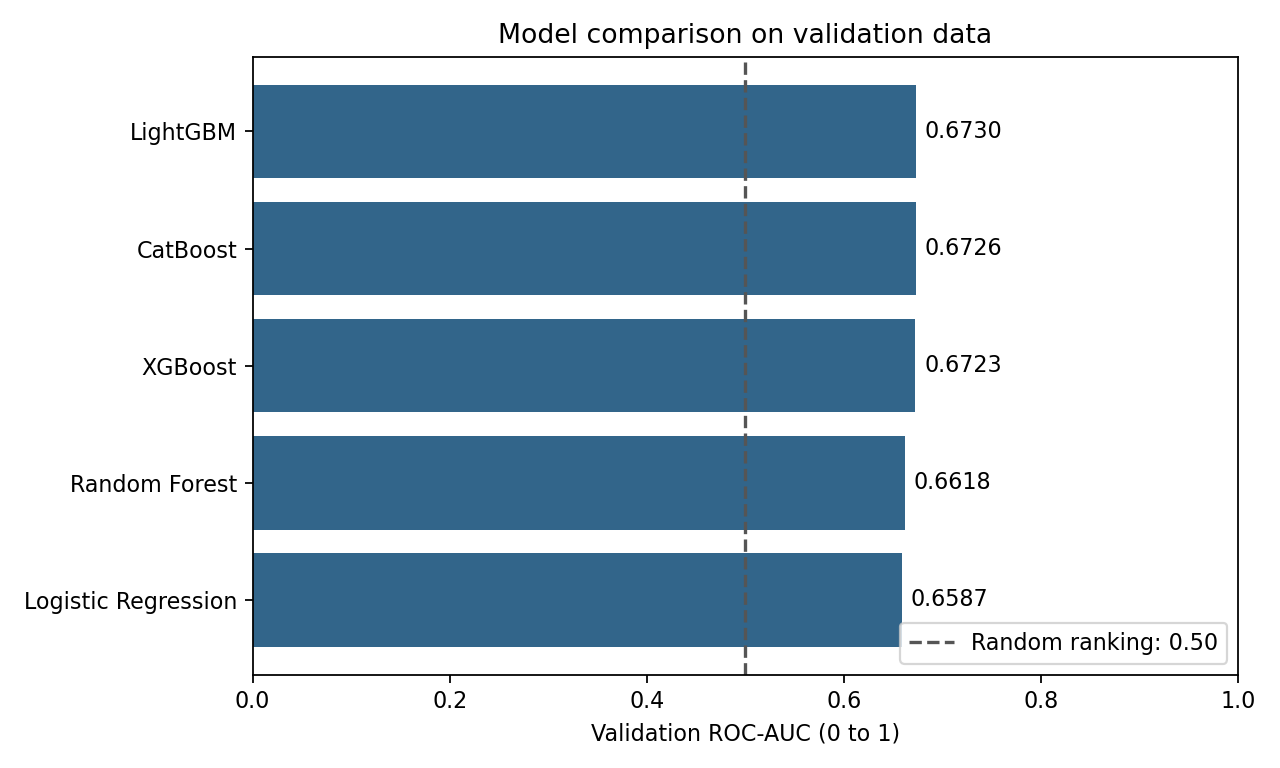

,threshold,roc_auc,average_precision,recall,precision,specificity,accuracy,review_share,tn,fp,fn,tp,scenario_cost,approve_all_cost,scenario_cost_reduction
0,0.585,0.672967,0.355536,0.416123,0.361762,0.796461,0.713903,0.249684,29078,7431,5910,4212,1.769378e+08,2.476764e+08,0.285609


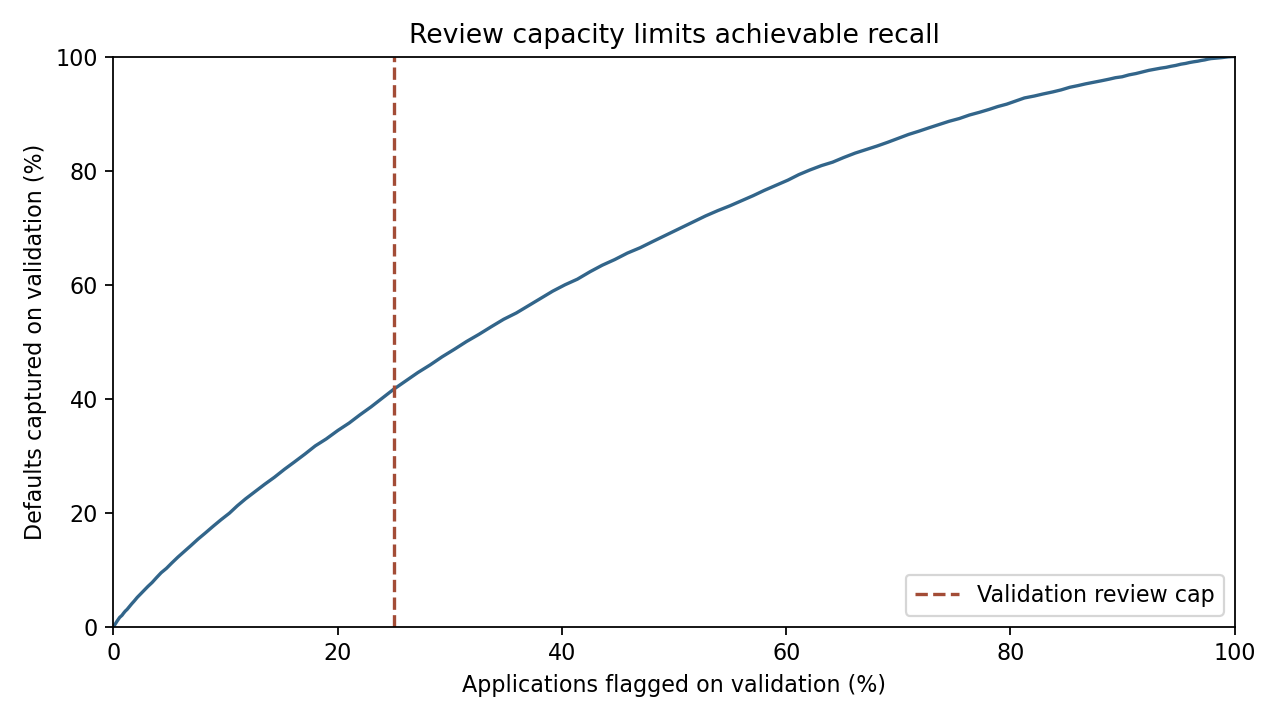

**Primary model: LightGBM**. Validation-selected cutoff: **0.585**.

In [11]:
comparison = table('model_comparison')
display(comparison)
chart('model_comparison')
display(pd.DataFrame([results['validation_policy']]))
chart('review_tradeoff')
display(Markdown(f'**Primary model: {results["selected_model"]}**. '
                 f'Validation-selected cutoff: **{results["validation_policy"]["threshold"]:.3f}**.'))

### 6.1 Cost and capacity sensitivity

Five capacities, three assumed loss rates, and three lost-margin rates generate
45 validation-only scenarios. Operational priorities may change the cutoff
even with an unchanged model. These are assumed-cost scenarios, not measured savings.

,review_cap,lgd_assumption,margin_assumption,threshold,review_share,recall,precision,scenario_cost_reduction
0,0.10,0.25,0.04,0.670,0.095880,0.187611,0.424737,0.146955
1,0.10,0.25,0.08,0.670,0.095880,0.187611,0.424737,0.106299
2,0.10,0.25,0.12,0.670,0.095880,0.187611,0.424737,0.065643
3,0.10,0.45,0.04,0.670,0.095880,0.187611,0.424737,0.165024
4,0.10,0.45,0.08,0.670,0.095880,0.187611,0.424737,0.142438
5,0.10,0.45,0.12,0.670,0.095880,0.187611,0.424737,0.119851
6,0.10,0.65,0.04,0.670,0.095880,0.187611,0.424737,0.171974
7,0.10,0.65,0.08,0.670,0.095880,0.187611,0.424737,0.156337
8,0.10,0.65,0.12,0.670,0.095880,0.187611,0.424737,0.140700
9,0.20,0.25,0.04,0.615,0.189702,0.329283,0.376780,0.242138


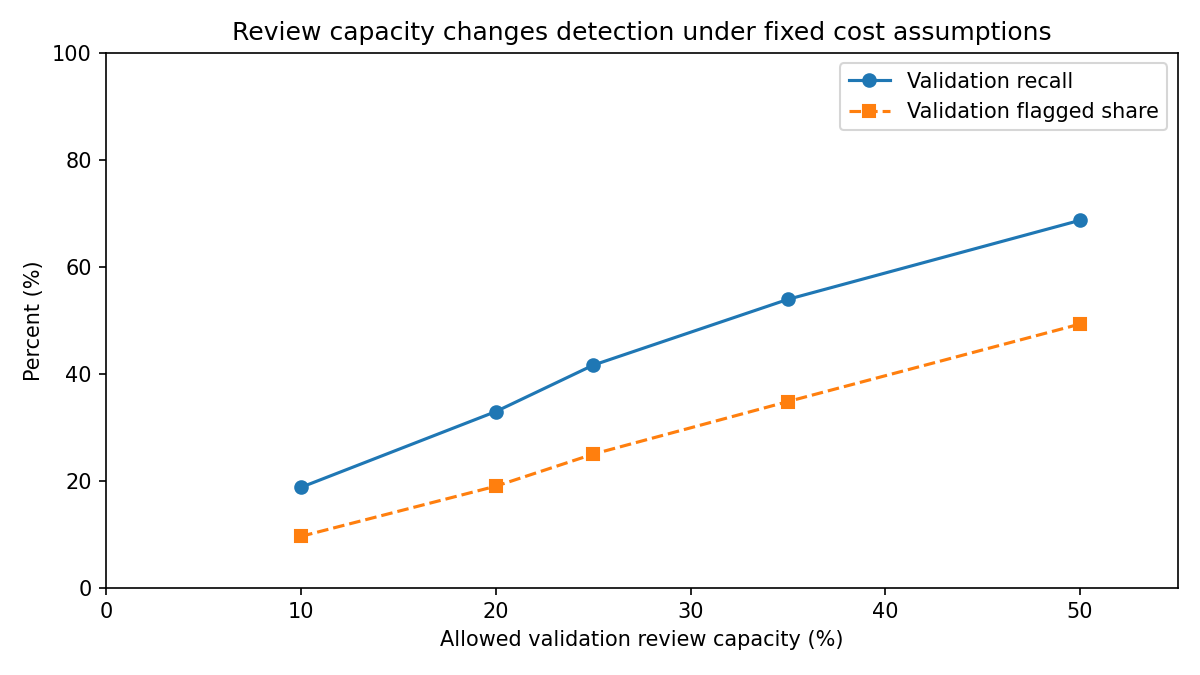

In [12]:
display(table('cost_capacity_sensitivity'))
chart('capacity_sensitivity')

## Stage 7 - Validation
### 7.1 Generalization and stability

Five outer folds assess the selected family in the training population. Each
refits imputation, target encoding, and the estimator. Fold SD describes variation,
not a future-performance confidence interval. Seed comparisons isolate estimator
randomness on fixed data. In-sample training AUC is only a fitting diagnostic.

,fold,fit_rows,holdout_rows,roc_auc,average_precision
0,1,111913,27979,0.676339,0.353912
1,2,111913,27979,0.676895,0.354985
2,3,111914,27978,0.678195,0.361001
3,4,111914,27978,0.673371,0.358216
4,5,111914,27978,0.674357,0.356845


,model_seed,validation_roc_auc,validation_average_precision
0,42,0.672967,0.355536
1,7,0.672869,0.355570
2,123,0.672940,0.355404
3,2024,0.673081,0.355627


,partition,roc_auc,average_precision
0,In-sample cross-fitted training representation,0.720444,0.408829
1,Validation,0.672967,0.355536


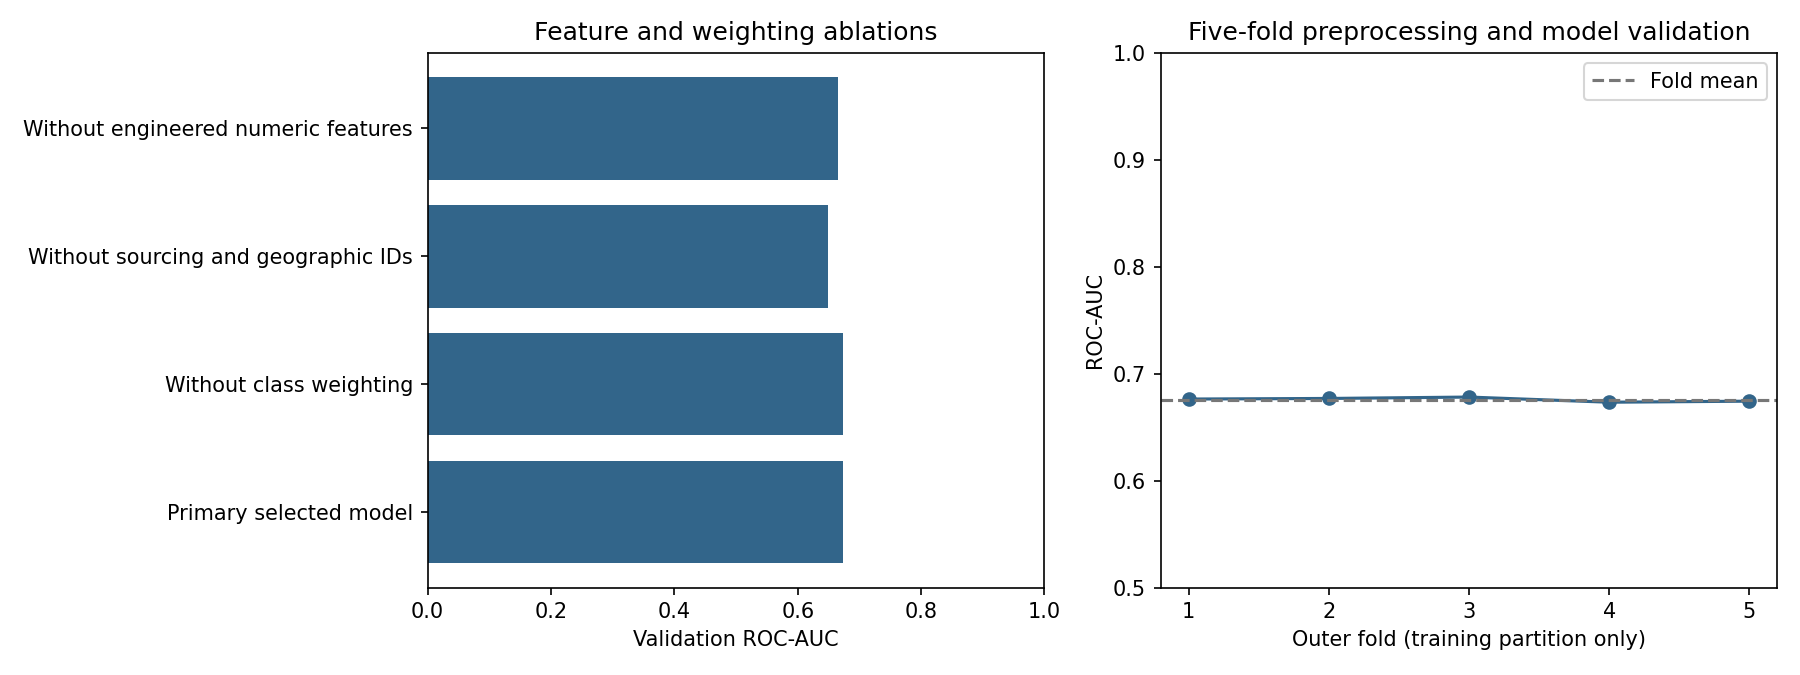

Outer-fold AUC: **0.6758 +/- 0.0019** (mean +/- fold sample SD). Four-seed validation AUC range: **0.0002**.

In [13]:
display(table('cross_validation'))
display(table('seed_stability'))
display(table('generalization_gap'))
chart('experiment_diagnostics')
exp = results['extended_experiments']
display(Markdown(f'Outer-fold AUC: **{exp["cv_auc_mean"]:.4f} +/- {exp["cv_auc_std"]:.4f}** '
                 f'(mean +/- fold sample SD). Four-seed validation AUC range: '
                 f'**{exp["seed_validation_auc_range"]:.4f}**.'))

### 7.2 Held-out outcomes and uncertainty

The model and cutoff are frozen before test evaluation. Cutoff 0.50 is a
predeclared reference, not a second policy selected on test labels. Pointwise
95% intervals use 200 stratified row-bootstrap samples, conditional on the frozen
model and observed prevalence. They exclude fitting uncertainty and entity dependence.

,policy,threshold,roc_auc,average_precision,recall,precision,accuracy,review_share
0,Approve all,1.000,0.500000,0.217066,0.000000,0.000000,0.782934,0.000000
1,Predeclared cutoff 0.50,0.500,0.673508,0.352894,0.638905,0.312990,0.617207,0.443096
2,Validation-selected cutoff,0.585,0.673508,0.352894,0.421755,0.358709,0.710815,0.255216


,metric,ci_low,ci_high,bootstrap_repetitions
0,roc_auc,0.667567,0.679287,200
1,average_precision,0.346571,0.360627,200
2,recall,0.412665,0.430849,200
3,precision,0.351741,0.365162,200
4,review_share,0.250899,0.258782,200


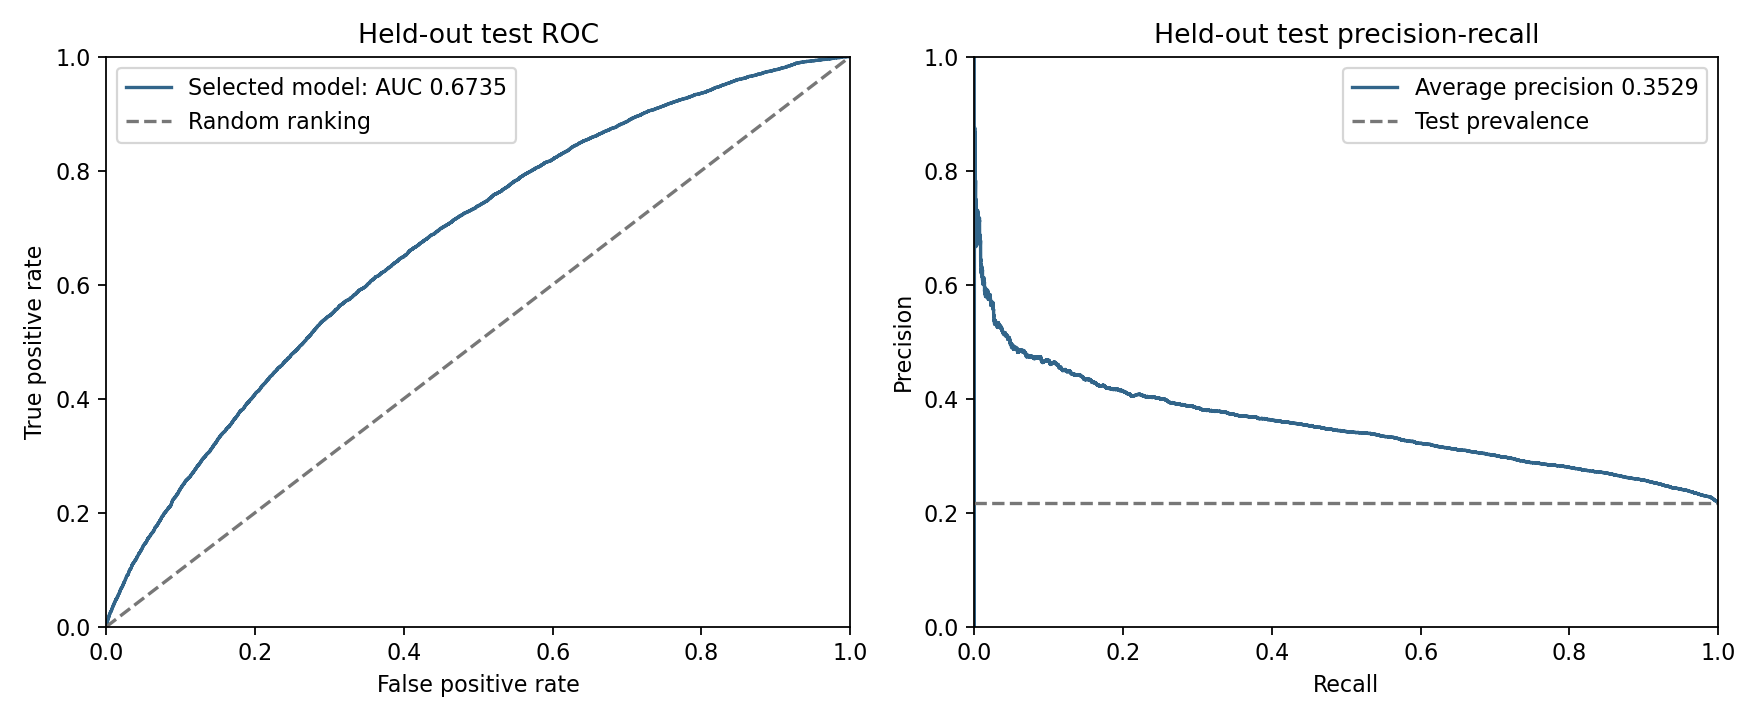

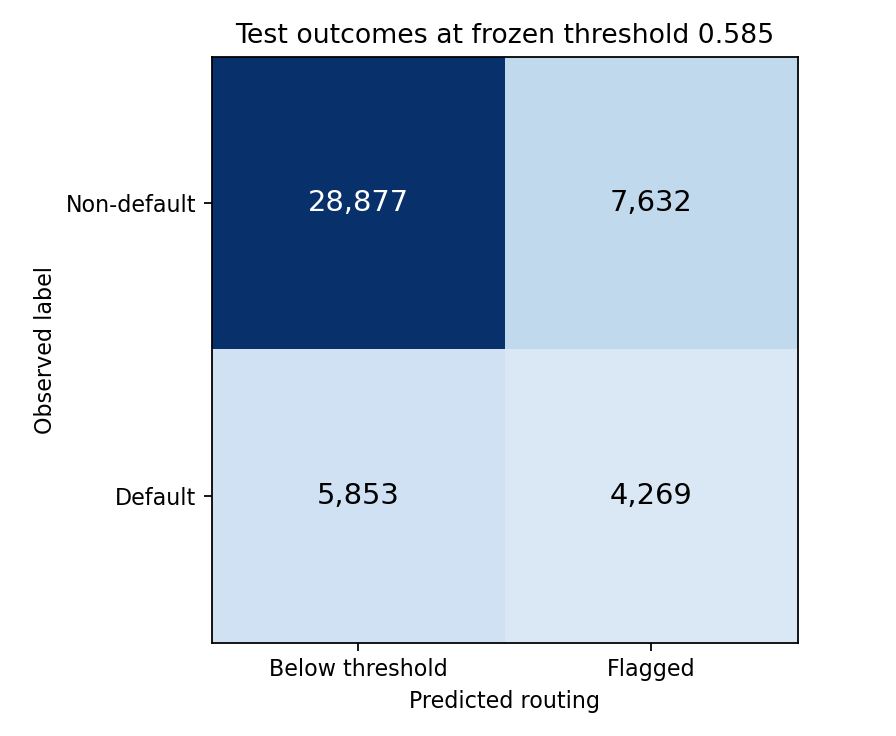

,feature,importance,importance_type
0,BRANCH_ID,2007,native model importance; not causal; scale dep...
1,CURRENT_PINCODE_ID,1969,native model importance; not causal; scale dep...
2,EMPLOYEE_CODE_ID,1861,native model importance; not causal; scale dep...
3,AGE_AT_DISBURSAL,1813,native model importance; not causal; scale dep...
4,SUPPLIER_ID,1724,native model importance; not causal; scale dep...
5,DISBURSED_AMOUNT,1667,native model importance; not causal; scale dep...
6,LTV,1614,native model importance; not causal; scale dep...
7,DISBURSAL_DAY,1431,native model importance; not causal; scale dep...
8,PERFORM_CNS_SCORE,1314,native model importance; not causal; scale dep...
9,STATE_ID,1312,native model importance; not causal; scale dep...


Test AUC **0.6735**; default recall **42.2%**; flagged share **25.5%**; precision **35.9%**.

In [14]:
policy = results['test_policy']
outcomes = pd.DataFrame([
    {'policy': 'Approve all', **results['test_approve_all']},
    {'policy': 'Predeclared cutoff 0.50', **results['test_at_050']},
    {'policy': 'Validation-selected cutoff', **policy},
])
display(outcomes[['policy', 'threshold', 'roc_auc', 'average_precision', 'recall', 'precision', 'accuracy', 'review_share']])
display(table('test_bootstrap_intervals'))
chart('test_ranking')
chart('confusion_matrix')
display(table('feature_importance').head(15))
display(Markdown(f'Test AUC **{policy["roc_auc"]:.4f}**; default recall **{policy["recall"]:.1%}**; '
                 f'flagged share **{policy["review_share"]:.1%}**; precision **{policy["precision"]:.1%}**.'))

### 7.3 Interpretation limits

Importance is descriptive and estimator-specific, not causal or an individual
lending explanation. This dataset was explored before this portfolio revision.
Random application splits may share sourcing entities across partitions and
are internal benchmarks, not untouched external or future-period validation.
Validation supports both model selection and policy fitting, leaving selection uncertainty.

In [15]:
display(Markdown(chr(10).join(f'- {item}' for item in results['limitations'])))

- Random application split; no out-of-time or unseen-entity validation.
- Validation set reused for model selection and policy choice; selection uncertainty remains.
- Class-weighted scores are uncalibrated and are not probability-of-default estimates.
- Review cap is fitted on validation; test or future flag rates can exceed it.
- Cost scenario assumes every flagged default loss is avoided and charges margin only for flagged non-defaults.
- Review does not itself prevent default; workload costs and actual interventions are not modeled.
- Geographic, staff, age, and identity-document features need fairness and availability review.
- Previously explored public dataset; held-out results are an internal benchmark, not external validation.

## Stage 8 - Model Deployment

```text
Application -> input checks -> training-fitted preprocessing -> model score
            -> frozen queue cutoffs -> human assessment -> recorded outcome
```

The offline code routes cases to lower-score, standard, and priority-review
queues. The high cutoff comes from stage 6. A low cutoff is fitted on validation
only: use the largest cutoff with at least 5% of cases (and 30 observations)
below it and observed default rate at most 10%. If none qualifies, disable that
queue. That fitted rate does not guarantee test or future outcomes.

Every queue retains normal assessment. No automatic approval or rejection is
implemented. APIs, registries, authentication, SLAs, individual explanations,
and lending-system integration remain proposed designs.

,status,low_score_threshold,high_score_threshold,low_queue_validation_max_observed_default_rate,low_queue_validation_min_share,routing_actions,monitoring_scope,bootstrap_repetitions,bootstrap_scope
0,offline routing and monitoring demonstration; ...,0.36,0.585,0.1,0.05,{'Lower-score queue': 'Normal underwriting; no...,training reference vs random validation split;...,200,"pointwise stratified row intervals, conditiona..."


,group,applications,defaults,default_rate,ci_low,ci_high,application_share
0,Lower-score queue,12727,1267,0.099552,0.094471,0.104875,0.272930
1,Standard review,22261,4643,0.208571,0.203284,0.213958,0.477386
2,Priority review,11643,4212,0.361762,0.353081,0.370535,0.249684


,group,applications,defaults,default_rate,ci_low,ci_high,application_share
0,Lower-score queue,12613,1225,0.097122,0.092076,0.102413,0.270485
1,Standard review,22117,4628,0.209251,0.203941,0.214662,0.474298
2,Priority review,11901,4269,0.358709,0.350139,0.367371,0.255216


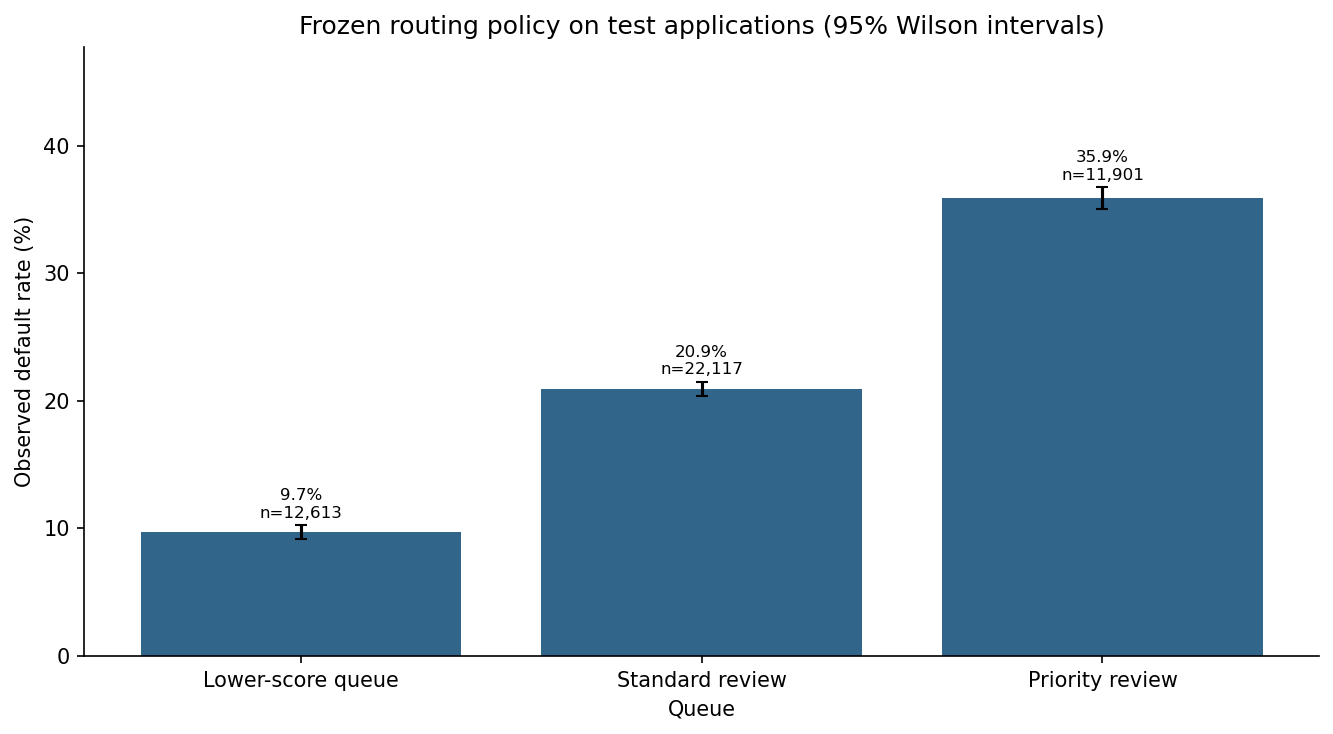

In [16]:
display(pd.DataFrame([results['operations']]))
display(table('validation_routing'))
display(table('test_routing'))
chart('risk_routing')

## Stage 9 - Model Monitoring, Feedback & Continuous Improvement

The executable demonstration compares training-reference feature distributions
with validation using reference-quantile PSI bins and an explicit missing bin.
It also reports unseen categorical shares. Both populations come from a random
split: this checks monitoring calculations and does not establish live stability.
No universal PSI alert threshold is assumed.

A future pilot needs workload, data-quality, mature-label performance,
calibration, subgroup, override, cost, and intervention monitoring. The plan is
a proposed process; no live scheduler or feedback integration is implemented.
A new challenger requires a new future-period holdout.

,feature,psi,training_missing_share,validation_missing_share
0,LTV,0.000265,0.0,0.0
1,DISBURSED_AMOUNT,0.000097,0.0,0.0
2,PERFORM_CNS_SCORE,0.000211,0.0,0.0
3,NO_OF_INQUIRIES,0.000026,0.0,0.0
4,AGE_AT_DISBURSAL,0.000354,0.0,0.0


,feature,training_categories,validation_unseen_share
0,SUPPLIER_ID,2876,0.001158
1,BRANCH_ID,82,0.000000
2,STATE_ID,22,0.000000
3,MANUFACTURER_ID,11,0.000000
4,CURRENT_PINCODE_ID,6261,0.006283
5,EMPLOYEE_CODE_ID,3245,0.000365
6,PERFORM_CNS_SCORE_DESCRIPTION,20,0.000000
7,EMPLOYMENT_TYPE,3,0.000000


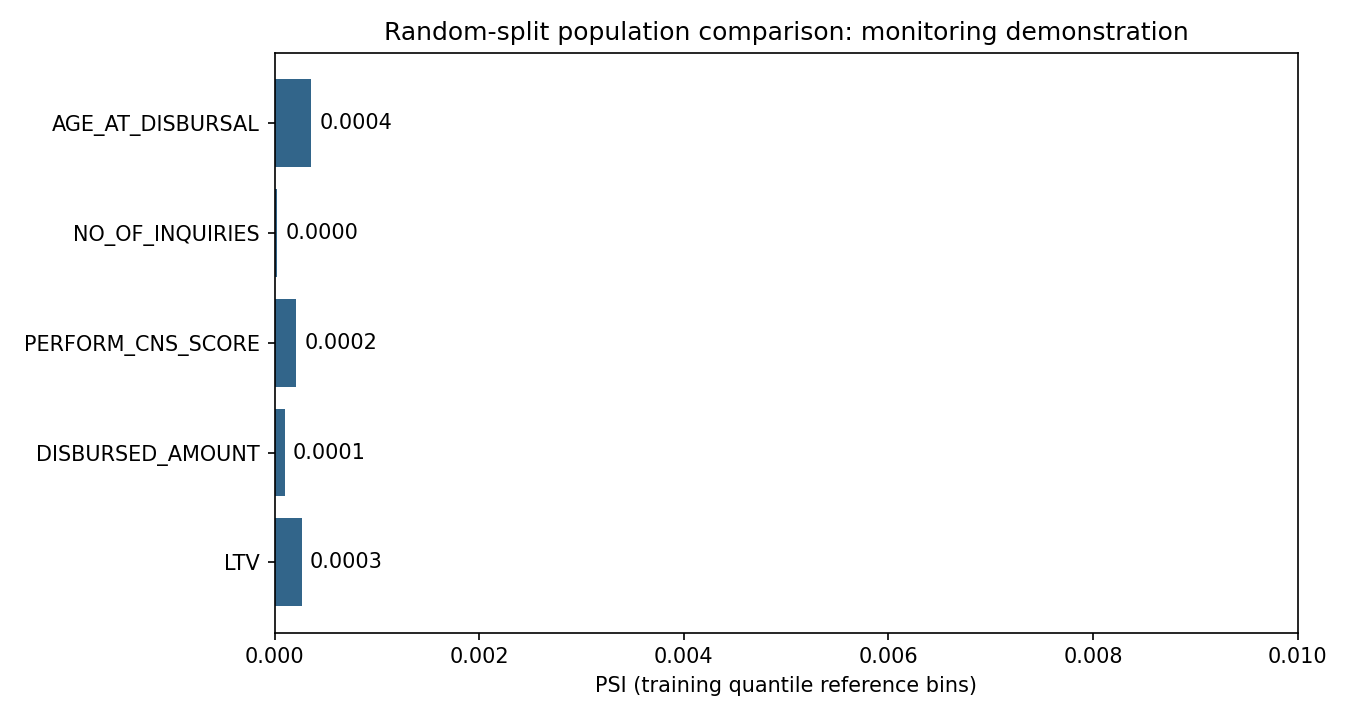

,signal,cadence,response
0,"Schema, missingness, invalid values",Every scoring batch,Quarantine malformed inputs; inspect upstream ...
1,Unseen sourcing categories and PSI,Compare each batch with training reference,Investigate population changes; thresholds req...
2,Flagged share vs review capacity,Daily queue review,Escalate capacity shortfalls; do not silently ...
3,"ROC-AUC, AP, recall, calibration, subgroup out...",Once outcome labels mature,Compare with frozen reference; investigate cha...
4,"Human overrides, review costs, intervention re...",Pilot review cycle,Replace illustrative costs with observed opera...
5,Versioned challenger evaluation,When data or policy changes justify a review,Validate on a new future-period holdout and re...


In [17]:
display(table('monitoring_feature_baseline'))
display(table('monitoring_unseen_categories'))
chart('monitoring_baseline')
display(table('monitoring_plan'))

## Stage 10 - Business Recommendations

Recommendations follow measured EDA, experiments, and held-out outcomes.
Risk prioritization is a candidate for a controlled pilot; this offline study
does not establish causal interventions or realized savings.

In [18]:
ablation = table('ablation_experiments').set_index('experiment')
delta = ablation.loc['Without sourcing and geographic IDs', 'auc_change_from_primary']
recommendations = pd.DataFrame([
    {'finding': f'Test recall {policy["recall"]:.1%} at {policy["review_share"]:.1%} flagged share',
     'recommendation': 'Pilot prioritized human review; measure missed defaults, workload, and intervention effectiveness'},
    {'finding': f'Training default {eda["training_ltv_above_80_default_rate"]:.1%} above 80% LTV vs {eda["training_ltv_at_most_80_default_rate"]:.1%} otherwise',
     'recommendation': 'Investigate loan structure with verified affordability data before changing terms'},
    {'finding': f'Removing sourcing/geographic IDs changes validation AUC by {delta:+.4f}',
     'recommendation': 'Test future-period and unseen-entity transfer; examine proxies and subgroup outcomes'},
    {'finding': f'Four-seed validation AUC range {exp["seed_validation_auc_range"]:.4f}',
     'recommendation': 'Version the experiment and validate challengers prospectively'},
    {'finding': '45 cost/capacity scenarios use assumed operating costs',
     'recommendation': 'Collect review time, recoveries, lost margins, and intervention outcomes'},
])
display(recommendations)
recommendations.to_csv(REPORTS / 'tables/business_recommendations.csv', index=False)
display(outcomes[['policy', 'scenario_cost', 'approve_all_cost', 'scenario_cost_reduction']])
display(Markdown(f'**Conclusion.** {results["selected_model"]} provides moderate risk ranking '
                 f'(test AUC **{policy["roc_auc"]:.4f}**, AP **{policy["average_precision"]:.4f}**). '
                 f'The frozen high cutoff changes assumed test error cost by **{policy["scenario_cost_reduction"]:.1%}** '
                 'versus approving all under the 45% loss / 8% margin scenario. '
                 'This assumes every flagged default loss can be prevented and omits review costs. '
                 'It is a conditional simulation. Prospective validation and measured intervention costs are the next priorities.'))

,finding,recommendation
0,Test recall 42.2% at 25.5% flagged share,Pilot prioritized human review; measure missed...
1,Training default 25.8% above 80% LTV vs 19.5% ...,Investigate loan structure with verified affor...
2,Removing sourcing/geographic IDs changes valid...,Test future-period and unseen-entity transfer;...
3,Four-seed validation AUC range 0.0002,Version the experiment and validate challenger...
4,45 cost/capacity scenarios use assumed operati...,"Collect review time, recoveries, lost margins,..."


,policy,scenario_cost,approve_all_cost,scenario_cost_reduction
0,Approve all,2.476764e+08,2.476764e+08,0.000000
1,Predeclared cutoff 0.50,1.511838e+08,2.476764e+08,0.389591
2,Validation-selected cutoff,1.764174e+08,2.476764e+08,0.287710


**Conclusion.** LightGBM provides moderate risk ranking (test AUC **0.6735**, AP **0.3529**). The frozen high cutoff changes assumed test error cost by **28.8%** versus approving all under the 45% loss / 8% margin scenario. This assumes every flagged default loss can be prevented and omits review costs. It is a conditional simulation. Prospective validation and measured intervention costs are the next priorities.

## Reproducibility and sources

```powershell
python -m pip install -r requirements.txt
python -m unittest discover -s tests -v
python src/credit_risk.py --data data/raw/train.csv --output reports
```

The notebook and CLI share Python modules. `metrics.json` records versions,
configuration, and the source fingerprint. EDA, experiments, routing, and
monitoring have JSON/CSV summaries. Raw records remain local and ignored by Git.

- [LTFS / Analytics Vidhya](https://www.analyticsvidhya.com/datahack/contest/ltfs-datascience-finhack-an-online-hackathon/)
- [Dataset mirror / Kaggle](https://www.kaggle.com/datasets/avikpaul4u/vehicle-loan-default-prediction)
- [TargetEncoder cross-fitting](https://scikit-learn.org/1.4/modules/generated/sklearn.preprocessing.TargetEncoder.html)
- [Cross-validation](https://scikit-learn.org/1.4/modules/cross_validation.html)
- [Wilson binomial interval reference](https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportion_confint.html)

See `data/README.md`, `METHODOLOGY.md`, and `reports/README.md` for details.

In [19]:
display(pd.DataFrame(results['versions'].items(), columns=['package', 'version']))
print('Input SHA-256:', results['data_sha256'])
print('Run type:', results['run_type'])

,package,version
0,numpy,1.26.4
1,pandas,2.2.2
2,scikit-learn,1.4.2
3,matplotlib,3.8.4
4,xgboost,3.2.0
5,lightgbm,4.7.0
6,catboost,1.2.10


Input SHA-256: bc3cfef743b956daf3f6142853f6272605f7bb425e2e0ad5de3b87da10e7c5f6
Run type: full_dataset
